# Adversarial Search: Playing "Mean" Connect 4


## Instructions

Total Points: Undegraduates 10, graduate students 11

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed.

## Introduction

You will implement different versions of agents that play "Mean" Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

> **The mean part:** This game has an additional rule. Every time it is a player's turn, the player can decide to instead of playing a new disk, take a bottom row disk of the opponent and place it in any column. All disks above the removed disk will fall down one position. Note that a player can only move an _opponent's disc_ that is in the _bottom row_ of the board.

Note that normal [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

## Hướng dẫn chạy notebook

Chạy lần lượt từ trên xuống dưới bằng **Run All**. Các bảng và biểu đồ sẽ được tạo từ kết quả thực nghiệm trên máy đang chạy notebook. Không điền số liệu giả vào báo cáo: hãy giữ lại output thực tế sau khi chạy.

Notebook dùng `numpy`, `pandas` và `matplotlib`. Nếu thiếu thư viện, cài bằng:
```bash
pip install numpy pandas matplotlib
```

Các thí nghiệm bàn lớn đều dùng cutoff hoặc rollout có giới hạn để thời gian chạy có thể kiểm soát. `max_plies` chỉ là giới hạn an toàn cho mô phỏng, không phải luật gốc của Mean Connect 4.

## Task 1: Defining the Search Problem [1 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states


## Trả lời Task 1 – Mô hình hóa bài toán tìm kiếm

**1. Trạng thái ban đầu (Initial state).** Bàn cờ chuẩn có 6 hàng và 7 cột, ban đầu tất cả ô đều rỗng. Mỗi ô được mã hóa bằng `0` (rỗng), `1` (RED – MAX) hoặc `-1` (YELLOW – MIN). Một trạng thái đầy đủ còn phải xác định người chơi đang đến lượt. Trong notebook, trạng thái được biểu diễn bởi cặp `(board, player)`.

**2. Các hành động (Actions).** Người chơi có thể chọn một trong hai loại:
- `('drop', c)`: thả một quân của mình vào cột `c` chưa đầy; quân rơi xuống ô trống thấp nhất.
- `('move', s, d)`: lấy quân của đối thủ ở hàng đáy cột nguồn `s`, làm các quân phía trên rơi xuống một hàng, rồi đặt quân vừa lấy vào ô trống thấp nhất của cột đích `d`.

Nước di chuyển cùng cột nguồn–đích được loại khỏi danh sách vì nó không làm thay đổi bàn cờ, không tạo tiến triển và chỉ làm tăng các chu trình vô ích trong tìm kiếm. Điều kiện quan trọng của Mean Move là quân được lấy phải nằm ở hàng đáy và thuộc đối thủ.

**3. Mô hình chuyển trạng thái (Transition model).** `result(s, a)` tạo một bản sao bàn cờ, thực hiện hành động trên bản sao và trả về bàn mới; bàn đầu vào không bị sửa. Với Drop, đặt quân người chơi hiện tại vào ô trống thấp nhất. Với Move, xóa quân đối thủ ở hàng đáy cột nguồn, dịch các quân còn lại xuống, sau đó thả quân bị lấy vào cột đích. Sau mỗi hành động, lượt chuyển cho đối thủ.

**4. Kiểm tra trạng thái kết thúc (Terminal test).** Ván đấu kết thúc khi RED hoặc YELLOW tạo được ít nhất `connect_n` quân liên tiếp theo hàng ngang, hàng dọc hoặc đường chéo; hoặc người tới lượt không còn hành động hợp lệ. Trong thí nghiệm, nếu số lượt vượt `max_plies`, mô phỏng được dừng và tính là hòa để tránh một chu trình kéo dài do Mean Move. Đây là giới hạn thực nghiệm, không phải luật gốc của trò chơi.

**5. Hàm utility.** Dùng quy ước cố định theo màu: `+1` nếu RED thắng, `-1` nếu YELLOW thắng, `0` nếu hòa hoặc chưa có người thắng. Nếu một trạng thái đặc biệt đồng thời có chuỗi thắng của cả hai màu, notebook quy ước là hòa (`0`) để tránh thiên vị. Trong Minimax, RED tối đa hóa utility và YELLOW tối thiểu hóa utility.


How big is the state space? Give an estimate and explain it.


## Ước lượng kích thước không gian trạng thái

Với bàn chuẩn 6 × 7, mỗi cột có thể chứa từ 0 đến 6 quân. Do các quân luôn nằm sát đáy (luật trọng lực), một cột có chiều cao `h` có `2^h` cách gán màu. Vì vậy số cấu hình hợp lệ theo trọng lực của một cột bị chặn trên bởi:

\[
1+2+2^2+\cdots+2^6 = 127.
\]

Xem 7 cột độc lập, số cấu hình bàn cờ có cận trên:

\[
|S_{board}| \le 127^7 = 532{,}875{,}860{,}165{,}503
\approx 5.33\times 10^{14}.
\]

Nếu tính thêm người đang đến lượt (RED hoặc YELLOW):

\[
|S| \le 2\times127^7 \approx 1.07\times10^{15}.
\]

Đây là **cận trên**, không phải số trạng thái thực sự có thể đạt tới. Nhiều cách gán màu không thể xuất hiện do luật luân phiên lượt, điều kiện thắng và quy tắc Mean Move. Tuy vậy, ngay cả cận trên này đã rất lớn, cho thấy không thể lưu hoặc duyệt toàn bộ không gian trạng thái bằng vét cạn thông thường.


How big is the game tree that minimax search will go through? Give an estimate and explain it.


## Ước lượng kích thước cây trò chơi

Ở một trạng thái bất kỳ, có tối đa 7 nước Drop (mỗi cột một nước). Với Mean Move, có tối đa 7 cột chứa quân đối thủ ở đáy; mỗi quân có thể được chuyển tới tối đa 6 cột đích khác. Do đó một cận trên thô cho số hành động là:

\[
b_{\max} \le 7 + 7\times6 = 49.
\]

Đây là cận trên rộng: không phải trạng thái nào cũng có đủ 7 quân đối thủ ở đáy, và không phải cột đích nào cũng còn chỗ. Với hệ số phân nhánh tối đa `b = 49`, số nút ở độ sâu `d` bị chặn bởi:

\[
N(d) \le 1+b+b^2+\cdots+b^d
=\frac{b^{d+1}-1}{b-1}.
\]

Ví dụ ở độ sâu 8, cận trên là khoảng \(3.39\times10^{13}\) nút. Vì vậy chi phí Minimax tăng theo hàm mũ theo độ sâu. Mean Move còn có thể tạo chu trình (một quân bị chuyển qua lại), nên nếu không có giới hạn lượt hoặc phát hiện trạng thái lặp thì cây trò chơi có thể không kết thúc. Trong code, đường đi tìm kiếm phát hiện trạng thái lặp và xem nhánh lặp là hòa; mô phỏng ván đấu có `max_plies` làm giới hạn an toàn.


## Task 2: Game Environment and Random Agent [3 point]

You can use a numpy character array as the board. Note that the following function can create boards of different sizes.

In [45]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


Instead of colors (red and yellow), you can use 1 and -1 to represent the players Max and Min. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position and player is the player (1, -1) whose next move it is and who the agent should play.

Visualization code by Randolph Rankin:

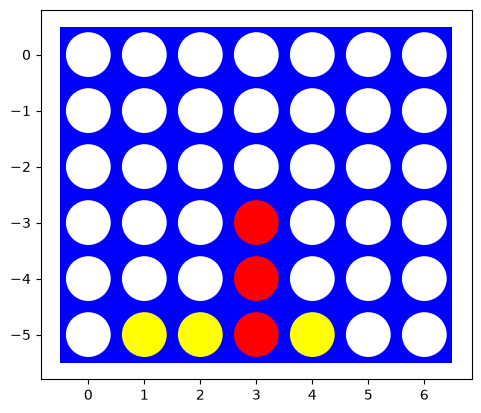

In [46]:
import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]

visualize(board)

Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

Make sure that all these functions work with boards of different sizes (number of columns and rows).

In [47]:
import numpy as np
import random
import time
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

RED = 1
YELLOW = -1
EMPTY = 0
DEFAULT_CONNECT = 4

def empty_board(shape=(6, 7)):
    """Tạo bàn rỗng; shape = (số hàng, số cột)."""
    return np.zeros(shape, dtype=np.int8)

def board_key(board, player):
    """Khóa trạng thái dùng để phát hiện chu trình trong tìm kiếm."""
    return (board.shape, board.tobytes(), int(player))

def get_winners(board, connect_n=DEFAULT_CONNECT):
    """Trả về tập người chơi đã có ít nhất một chuỗi connect_n."""
    board = np.asarray(board)
    rows, cols = board.shape
    winners = set()
    directions = [(0, 1), (1, 0), (1, 1), (1, -1)]

    for r in range(rows):
        for c in range(cols):
            player = int(board[r, c])
            if player == EMPTY:
                continue
            for dr, dc in directions:
                end_r = r + (connect_n - 1) * dr
                end_c = c + (connect_n - 1) * dc
                if not (0 <= end_r < rows and 0 <= end_c < cols):
                    continue
                if all(board[r + k * dr, c + k * dc] == player
                       for k in range(connect_n)):
                    winners.add(player)
    return winners

def utility(board, connect_n=DEFAULT_CONNECT):
    """
    Utility cố định theo màu:
    +1: RED thắng; -1: YELLOW thắng; 0: hòa/chưa có người thắng.
    Nếu cả hai cùng có connect_n (trường hợp đặc biệt sau Mean Move),
    quy ước là hòa để kết quả không thiên vị người chơi nào.
    """
    winners = get_winners(board, connect_n)
    if winners == {RED}:
        return 1
    if winners == {YELLOW}:
        return -1
    return 0

def actions(board, player, connect_n=DEFAULT_CONNECT):
    """
    Sinh hành động hợp lệ cho người chơi hiện tại.
    ('drop', col): thả quân của mình.
    ('move', source, destination): lấy quân đối thủ ở hàng đáy,
    loại bỏ nó khỏi cột nguồn (các quân phía trên rơi xuống), rồi
    thả quân đó vào cột đích còn chỗ.
    Nước move source == destination bị bỏ qua vì không làm đổi trạng thái.
    """
    board = np.asarray(board)
    rows, cols = board.shape

    if get_winners(board, connect_n):
        return []

    legal = []
    # Drop: cột còn ít nhất một ô trống.
    for col in range(cols):
        if board[0, col] == EMPTY:
            legal.append(("drop", col))

    # Mean Move: quân ở hàng đáy phải thuộc đối thủ.
    for source in range(cols):
        if board[rows - 1, source] != -player:
            continue
        for destination in range(cols):
            if destination == source:
                continue
            if board[0, destination] == EMPTY:
                legal.append(("move", source, destination))

    return legal

def result(board, action, player, connect_n=DEFAULT_CONNECT):
    """Trả về bàn mới sau hành động; không sửa bàn đầu vào."""
    board = np.asarray(board)
    new_board = board.copy()
    rows, cols = new_board.shape

    if action is None:
        raise ValueError("Không thể thực hiện action=None.")

    if action[0] == "drop":
        col = int(action[1])
        if not (0 <= col < cols) or new_board[0, col] != EMPTY:
            raise ValueError(f"Nước drop không hợp lệ: {action}")
        empty_rows = np.where(new_board[:, col] == EMPTY)[0]
        if len(empty_rows) == 0:
            raise ValueError(f"Cột {col} đã đầy.")
        new_board[empty_rows[-1], col] = player

    elif action[0] == "move":
        source, destination = int(action[1]), int(action[2])
        if not (0 <= source < cols and 0 <= destination < cols):
            raise ValueError(f"Cột không hợp lệ: {action}")
        if source == destination:
            raise ValueError("Move cùng cột là nước đi không làm thay đổi bàn.")
        if new_board[rows - 1, source] != -player:
            raise ValueError("Chỉ được di chuyển quân đối thủ ở hàng đáy.")
        if new_board[0, destination] != EMPTY:
            raise ValueError("Cột đích đã đầy.")

        moved_disc = int(new_board[rows - 1, source])
        # Loại bỏ quân đáy: các quân phía trên rơi xuống một hàng.
        new_board[1:, source] = new_board[:-1, source].copy()
        new_board[0, source] = EMPTY

        # Thả quân vừa lấy vào vị trí thấp nhất còn trống ở cột đích.
        empty_rows = np.where(new_board[:, destination] == EMPTY)[0]
        if len(empty_rows) == 0:
            raise ValueError("Không còn chỗ trong cột đích.")
        new_board[empty_rows[-1], destination] = moved_disc
    else:
        raise ValueError(f"Loại action không được hỗ trợ: {action}")

    return new_board

def terminal(board, player=None, connect_n=DEFAULT_CONNECT):
    """Kiểm tra kết thúc: có người thắng hoặc người tới lượt không còn nước đi."""
    if get_winners(board, connect_n):
        return True
    if player is not None:
        return len(actions(board, player, connect_n)) == 0
    return (len(actions(board, RED, connect_n)) == 0 and
            len(actions(board, YELLOW, connect_n)) == 0)

def visualize(board, title=None):
    """Vẽ bàn cờ với RED màu đỏ, YELLOW màu vàng."""
    board = np.asarray(board)
    rows, cols = board.shape
    fig, ax = plt.subplots(figsize=(max(5, cols * 0.8), max(4, rows * 0.7)))
    ax.set_facecolor("#1769aa")
    ax.set_xlim(-0.5, cols - 0.5)
    ax.set_ylim(rows - 0.5, -0.5)
    ax.set_aspect("equal")
    for r in range(rows):
        for c in range(cols):
            color = "white" if board[r, c] == EMPTY else (
                "red" if board[r, c] == RED else "yellow")
            circle = plt.Circle((c, r), 0.38, facecolor=color,
                                edgecolor="black", linewidth=0.7)
            ax.add_patch(circle)
    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.grid(False)
    if title:
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

### Giải thích môi trường và thiết kế biểu diễn

Bàn cờ là mảng NumPy hai chiều `rows × columns`; chỉ số hàng tăng từ trên xuống dưới, vì vậy `board[-1, col]` là ô đáy và `board[0, col]` là ô trên cùng. Quy ước `RED=1` và `YELLOW=-1` giúp hàm utility trả về điểm số cố định cho Minimax.

Các hàm môi trường được tách riêng:
- `actions(board, player)` liệt kê mọi Drop và Mean Move hợp lệ.
- `result(board, action, player)` tạo trạng thái kế tiếp mà không sửa bàn gốc.
- `get_winners` kiểm tra bốn hướng ngang, dọc và hai đường chéo.
- `utility` trả điểm kết quả; `terminal` kiểm tra trạng thái kết thúc.

Việc tách các hàm này giúp cùng một môi trường được tái sử dụng bởi Random, Minimax, Heuristic và Monte Carlo. Các hàm nhận `connect_n` và dùng kích thước thực tế của mảng nên có thể chạy trên bàn nhỏ hoặc bàn chuẩn.

Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on bt yhe environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [48]:
def random_player(board, player=None):
    """Chọn ngẫu nhiên một hành động hợp lệ."""
    if player is None:
        raise ValueError("Mean Connect 4 cần biết player = 1 hoặc -1.")
    legal = actions(board, player)
    return random.choice(legal) if legal else None

def play_game(red_agent, yellow_agent, shape=(6, 7),
              connect_n=4, max_plies=200, verbose=False):
    """
    Chơi một ván. winner: +1 RED, -1 YELLOW, 0 hòa.
    max_plies là giới hạn an toàn cho mô phỏng vì Mean Move có thể tạo chu trình.
    """
    board = empty_board(shape)
    player = RED
    agents = {RED: red_agent, YELLOW: yellow_agent}
    history = []

    for ply in range(max_plies):
        if utility(board, connect_n) != 0:
            break
        legal = actions(board, player, connect_n)
        if not legal:
            break

        action = agents[player](board.copy(), player)
        if action not in legal:
            raise ValueError(
                f"Agent {player} trả về nước không hợp lệ {action}; "
                f"các nước hợp lệ: {legal}"
            )

        board = result(board, action, player, connect_n)
        history.append((player, action))
        if verbose:
            print(f"Lượt {ply + 1}: player={player}, action={action}")
            visualize(board)

        if utility(board, connect_n) != 0:
            break
        player *= -1

    winner = utility(board, connect_n)
    # Nếu hết nước đi hoặc chạm giới hạn số lượt thì quy ước hòa.
    return {
        "winner": winner,
        "plies": len(history),
        "board": board,
        "history": history,
        "capped": len(history) >= max_plies
    }

def play_many(red_agent, yellow_agent, n_games=1000,
              shape=(6, 7), connect_n=4, max_plies=200, seed=42):
    """Chạy nhiều ván và trả về bảng tổng kết."""
    random.seed(seed)
    np.random.seed(seed)
    records = []
    for game_id in range(n_games):
        outcome = play_game(red_agent, yellow_agent, shape, connect_n, max_plies)
        records.append({
            "game": game_id + 1,
            "winner": outcome["winner"],
            "plies": outcome["plies"],
            "capped": outcome["capped"]
        })

    df = pd.DataFrame(records)
    counts = Counter(df["winner"])
    summary = pd.DataFrame([
        {"Player": "RED", "Wins": counts.get(RED, 0)},
        {"Player": "YELLOW", "Wins": counts.get(YELLOW, 0)},
        {"Player": "Draw", "Wins": counts.get(0, 0)}
    ])
    summary["Rate (%)"] = 100 * summary["Wins"] / n_games
    return df, summary

### Random Agent

`random_player(board, player)` nhận bàn cờ và người chơi hiện tại, gọi `actions` để lấy danh sách nước hợp lệ rồi chọn ngẫu nhiên một nước. Agent không lưu trạng thái nội bộ; toàn bộ thông tin cần thiết nằm trong `board` và `player`. Nếu không có nước hợp lệ, hàm trả về `None`.

Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [49]:
# Chạy đúng 1.000 ván Random Agent vs Random Agent trên bàn chuẩn 6x7.
random_games_df, random_summary_df = play_many(
    random_player, random_player,
    n_games=1000, shape=(6, 7), connect_n=4,
    max_plies=200, seed=42
)
display(random_summary_df)
print("Số ván chạm giới hạn max_plies:", int(random_games_df["capped"].sum()))
print("Số lượt trung bình mỗi ván:", round(random_games_df["plies"].mean(), 2))
display(random_games_df.head())

,Player,Wins,Rate (%)
0,RED,751,75.1
1,YELLOW,241,24.1
2,Draw,8,0.8


Số ván chạm giới hạn max_plies: 0
Số lượt trung bình mỗi ván: 24.23


,game,winner,plies,capped
0,1,1,12,False
1,2,-1,38,False
2,3,1,22,False
3,4,1,13,False
4,5,1,8,False


### Phân tích kết quả Random Agent

**Kết quả lần chạy hiện tại (1.000 ván, seed 42):** RED thắng 751 ván (75,1%), YELLOW thắng 241 ván (24,1%) và hòa 8 ván (0,8%). Không có ván nào chạm giới hạn 200 lượt; số lượt trung bình là 24,23. Chênh lệch lớn cho thấy lợi thế đi trước của RED rất rõ trong cấu hình Random-vs-Random này. Đây là kết quả thực nghiệm của cách mô hình hóa và chính sách chọn nước ngẫu nhiên đang dùng, không phải định lý rằng RED luôn thắng 75,1%.

## Task 3: Minimax Search with Alpha-Beta Pruning [3 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for a $6 \times 7$ board is large. You can experiment with smaller boards (the smallest is $4 \times 4$) and/or changing the winning rule to connect 3 instead of 4.

In [50]:
def center_order(board, action):
    """Điểm ưu tiên đơn giản: cột gần trung tâm được xét trước."""
    cols = board.shape[1]
    center = (cols - 1) / 2
    if action[0] == "drop":
        col = action[1]
    else:
        col = action[2]  # ưu tiên cột đích ở gần trung tâm
    return -abs(col - center)

def order_moves(board, legal_actions, player, connect_n=4):
    """
    Move ordering: nước thắng ngay trước, sau đó ưu tiên cột trung tâm.
    Điểm được tính theo góc nhìn người đang đi nên luôn sắp giảm dần.
    """
    scored = []
    for action in legal_actions:
        child = result(board, action, player, connect_n)
        u = utility(child, connect_n)
        if u * player == 1:
            score = 1_000_000
        elif u * player == -1:
            score = -1_000_000
        else:
            score = center_order(board, action)
        scored.append((score, action))
    scored.sort(key=lambda item: item[0], reverse=True)
    return [action for _, action in scored]

def minimax_alpha_beta(board, player=RED, connect_n=4,
                       max_depth=4, use_ordering=True):
    """
    Minimax + Alpha-Beta.
    Điểm utility cố định theo RED (+1) và YELLOW (-1).
    max_depth=None là tìm đến trạng thái kết thúc; không nên chạy từ bàn 6x7 rỗng.
    Khi chạm cutoff, phiên bản Task 3 trả về 0 (đánh giá trung tính).
    """
    stats = {"nodes": 0, "cutoffs": 0, "cycle_returns": 0}
    legal_root = actions(board, player, connect_n)
    if not legal_root:
        return None, stats

    def search(state, to_move, depth, alpha, beta, path):
        stats["nodes"] += 1
        u = utility(state, connect_n)
        if u != 0:
            return u
        if depth == 0:
            return 0

        key = board_key(state, to_move)
        if key in path:
            stats["cycle_returns"] += 1
            return 0
        next_path = path | {key}

        legal = actions(state, to_move, connect_n)
        if not legal:
            return 0
        if use_ordering:
            legal = order_moves(state, legal, to_move, connect_n)

        if to_move == RED:
            value = -float("inf")
            for action in legal:
                child = result(state, action, to_move, connect_n)
                next_depth = None if depth is None else depth - 1
                value = max(value, search(
                    child, -to_move, next_depth, alpha, beta, next_path))
                alpha = max(alpha, value)
                if alpha >= beta:
                    stats["cutoffs"] += 1
                    break
        else:
            value = float("inf")
            for action in legal:
                child = result(state, action, to_move, connect_n)
                next_depth = None if depth is None else depth - 1
                value = min(value, search(
                    child, -to_move, next_depth, alpha, beta, next_path))
                beta = min(beta, value)
                if alpha >= beta:
                    stats["cutoffs"] += 1
                    break
        return value

    root_actions = (order_moves(board, legal_root, player, connect_n)
                    if use_ordering else legal_root)
    best_action = root_actions[0]
    best_value = -float("inf") if player == RED else float("inf")
    alpha, beta = -float("inf"), float("inf")
    root_path = frozenset({board_key(board, player)})

    for action in root_actions:
        child = result(board, action, player, connect_n)
        value = search(child, -player,
                       None if max_depth is None else max_depth - 1,
                       alpha, beta, root_path)
        if player == RED and value > best_value:
            best_value, best_action = value, action
        elif player == YELLOW and value < best_value:
            best_value, best_action = value, action

        if player == RED:
            alpha = max(alpha, best_value)
        else:
            beta = min(beta, best_value)

    stats["best_value"] = best_value
    return best_action, stats

def minimax_player(board, player=RED):
    action, _ = minimax_alpha_beta(board, player, max_depth=4)
    return action

### Minimax và Alpha-Beta

Minimax giả định hai người chơi chọn hành động tối ưu: RED (MAX) cố gắng làm utility tăng, YELLOW (MIN) cố gắng làm utility giảm. Mỗi nút sinh các trạng thái con bằng `result`; thuật toán luân phiên người chơi cho đến khi gặp trạng thái kết thúc hoặc đạt cutoff.

Alpha-Beta duy trì hai cận: `alpha` là giá trị tốt nhất MAX đã bảo đảm, `beta` là giá trị tốt nhất MIN đã bảo đảm. Khi `alpha >= beta`, những nhánh còn lại tại nút hiện tại không thể ảnh hưởng quyết định nên được cắt. Code có phát hiện trạng thái lặp trên đường tìm kiếm và xem nhánh lặp là hòa. Với `max_depth=None`, hàm biểu diễn tìm kiếm đến kết thúc nhưng không nên chạy từ bàn chuẩn rỗng vì cây quá lớn.

Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

RED wins horizontally | chosen: ('drop', 3) | stats: {'nodes': 37, 'cutoffs': 18, 'cycle_returns': 0, 'best_value': 1}


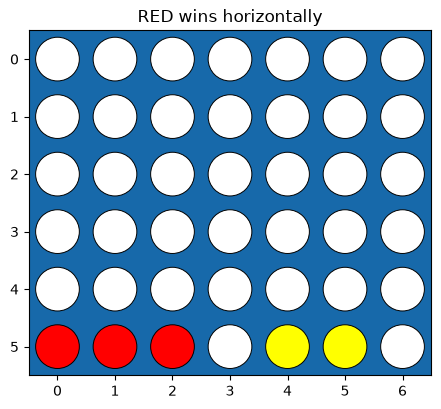

RED blocks YELLOW | chosen: ('drop', 3) | stats: {'nodes': 74, 'cutoffs': 24, 'cycle_returns': 0, 'best_value': 0}


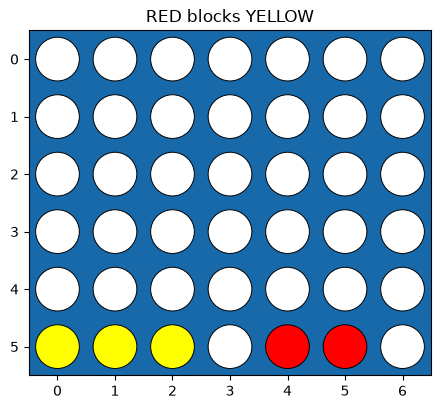

RED wins vertically | chosen: ('drop', 0) | stats: {'nodes': 13, 'cutoffs': 6, 'cycle_returns': 0, 'best_value': 1}


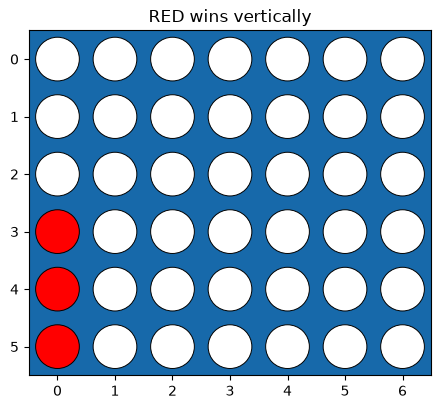

RED wins diagonally | chosen: ('drop', 3) | stats: {'nodes': 45, 'cutoffs': 20, 'cycle_returns': 0, 'best_value': 1}


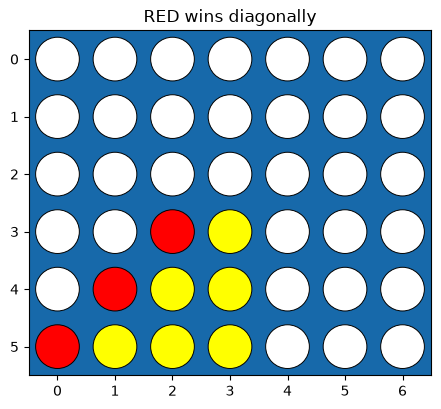

Mean Move creates a RED win | chosen: ('move', 3, 0) | stats: {'nodes': 20, 'cutoffs': 7, 'cycle_returns': 0, 'best_value': 1}


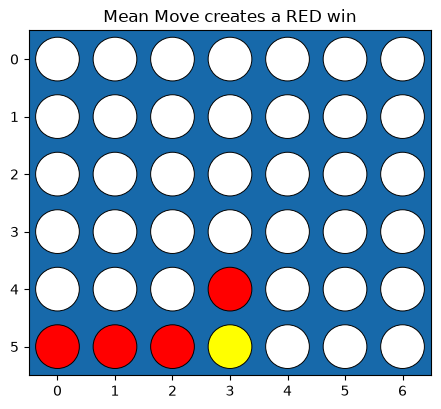

,Board,Player,Chosen action,Nodes,Cutoffs,Value
0,RED wins horizontally,1,"(drop, 3)",37,18,1
1,RED blocks YELLOW,1,"(drop, 3)",74,24,0
2,RED wins vertically,1,"(drop, 0)",13,6,1
3,RED wins diagonally,1,"(drop, 3)",45,20,1
4,Mean Move creates a RED win,1,"(move, 3, 0)",20,7,1


Các Mean Move hợp lệ ở bàn số 5: [('move', 3, 0), ('move', 3, 1), ('move', 3, 2), ('move', 3, 4), ('move', 3, 5), ('move', 3, 6)]
Nước được minh họa: ('move', 3, 0)
Bàn trước Mean Move:


,0,1,2,3,4,5,6
0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0
4,0,0,0,1,0,0,0
5,1,1,1,-1,0,0,0


Bàn sau Mean Move:


,0,1,2,3,4,5,6
0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0
4,-1,0,0,0,0,0,0
5,1,1,1,1,0,0,0


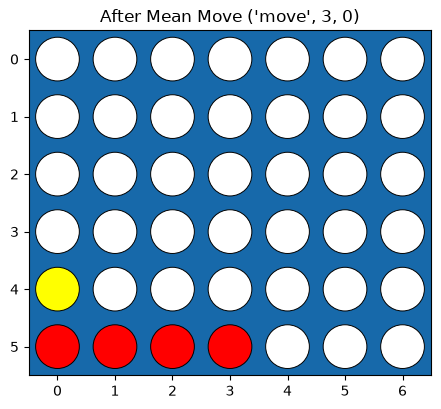

In [51]:
def board_from_columns(columns, shape=(6, 7)):
    """
    Tạo bàn từ danh sách quân theo từng cột, thứ tự từ đáy lên.
    Ví dụ columns[0] = [1, -1] nghĩa là đáy cột 0 là RED,
    phía trên là YELLOW.
    """
    board = empty_board(shape)
    rows, cols = shape
    for col, values in enumerate(columns):
        if col >= cols or len(values) > rows:
            raise ValueError("Dữ liệu cột vượt kích thước bàn.")
        for offset, value in enumerate(values):
            board[rows - 1 - offset, col] = value
    return board

test_boards = []

# 1. RED có thể thắng ngay theo hàng ngang ở cột 3.
b1 = board_from_columns([[RED], [RED], [RED], [], [YELLOW], [YELLOW], []])
test_boards.append(("RED wins horizontally", b1, RED))

# 2. RED cần chặn chuỗi ba YELLOW ở đáy.
b2 = board_from_columns([[YELLOW], [YELLOW], [YELLOW], [], [RED], [RED], []])
test_boards.append(("RED blocks YELLOW", b2, RED))

# 3. RED có thể thắng theo cột dọc.
b3 = board_from_columns([[RED, RED, RED], [], [], [], [], [], []])
test_boards.append(("RED wins vertically", b3, RED))

# 4. RED hoàn thành đường chéo bằng cách thả vào cột 3.
b4 = board_from_columns([
    [RED], [YELLOW, RED], [YELLOW, YELLOW, RED],
    [YELLOW, YELLOW, YELLOW], [], [], []
])
test_boards.append(("RED wins diagonally", b4, RED))

# 5. Có nước Mean Move hợp lệ: RED có thể chuyển quân YELLOW ở đáy cột 3.
b5 = board_from_columns([[RED], [RED], [RED], [YELLOW, RED], [], [], []])
test_boards.append(("Mean Move creates a RED win", b5, RED))

manual_results = []
for name, board, player in test_boards:
    action, stats = minimax_alpha_beta(
        board, player, connect_n=4, max_depth=2, use_ordering=True
    )
    manual_results.append({
        "Board": name,
        "Player": player,
        "Chosen action": action,
        "Nodes": stats["nodes"],
        "Cutoffs": stats["cutoffs"],
        "Value": stats.get("best_value")
    })
    print(name, "| chosen:", action, "| stats:", stats)
    visualize(board, title=name)

manual_results_df = pd.DataFrame(manual_results)
display(manual_results_df)

# Kiểm tra riêng luật Mean Move trên bàn số 5.
mean_move_candidates = [
    action for action in actions(b5, RED, connect_n=4)
    if action[0] == "move"
]
print("Các Mean Move hợp lệ ở bàn số 5:", mean_move_candidates)
if mean_move_candidates:
    sample_move = mean_move_candidates[0]
    after_mean_move = result(b5, sample_move, RED, connect_n=4)
    print("Nước được minh họa:", sample_move)
    print("Bàn trước Mean Move:")
    display(pd.DataFrame(b5))
    print("Bàn sau Mean Move:")
    display(pd.DataFrame(after_mean_move))
    visualize(after_mean_move, title=f"After Mean Move {sample_move}")

### Kiểm thử Minimax trên 5 bàn cờ

Năm trạng thái được thiết kế để kiểm tra các tình huống khác nhau: RED có thể thắng ngang, RED phải ngăn chuỗi ba của YELLOW, thắng dọc, thắng chéo và trạng thái có nước Mean Move. Cột `Chosen action` cho biết hành động được chọn; `Nodes` và `Cutoffs` lần lượt là số nút đã xét và số lần cắt tỉa Alpha-Beta.

Ở các bàn có nước thắng ngay, tác tử cần ưu tiên hành động tạo chiến thắng. Với bàn có đe dọa của đối thủ, độ sâu ít nhất 2 cho phép tìm một lượt của đối thủ sau hành động hiện tại. Riêng bàn Mean Move, cần kiểm tra danh sách hành động có chứa dạng `('move', source, destination)` và kết quả chuyển trạng thái có đúng luật hay không. Bản Minimax Task 3 dùng giá trị 0 tại cutoff, vì vậy đây là baseline tìm kiếm nông chứ chưa phải đánh giá chiến lược dài hạn.

**Kết quả lần chạy:** Minimax chọn `('drop', 3)` cho thắng ngang, chặn YELLOW và thắng chéo; chọn `('drop', 0)` cho thắng dọc. Ở bàn Mean Move, thuật toán chọn `('move', 3, 0)`: lấy quân YELLOW ở đáy cột 3, làm quân RED phía trên rơi xuống đáy và tạo thành bốn quân RED liên tiếp. Đây là minh chứng quan trọng rằng tác tử không chỉ xét Drop mà còn nhận diện được nước Mean Move tạo chiến thắng.


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

,Rows,Columns,Connect,Depth,Ordering,Mean time (s),Std time (s),Mean nodes,Mean cutoffs
0,4,4,3,3,True,0.003419,0.000897,45.0,9.0
1,4,5,3,3,True,0.004157,0.001205,67.0,12.0
2,4,6,3,3,True,0.004884,0.000304,93.0,15.0
3,4,7,3,3,True,0.008003,0.001414,123.0,18.0


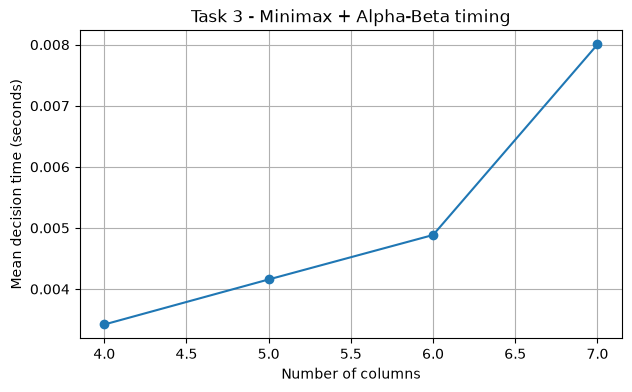

Minimax + Alpha-Beta trên bàn chuẩn 6x7:


,Rows,Columns,Connect,Depth,Ordering,Mean time (s),Std time (s),Mean nodes,Mean cutoffs
0,6,7,4,3,True,0.017816,0.000867,123.0,18.0


In [52]:
def benchmark_minimax(widths=(4, 5, 6, 7), rows=4, connect_n=3,
                      depth=3, repeats=5, use_ordering=True):
    """Đo thời gian chọn nước đầu tiên khi tăng số cột."""
    records = []
    for cols in widths:
        board = empty_board((rows, cols))
        # Warm-up để giảm ảnh hưởng của chi phí khởi tạo ở lần gọi đầu.
        minimax_alpha_beta(
            board, RED, connect_n=connect_n,
            max_depth=depth, use_ordering=use_ordering
        )
        times, node_counts, cutoff_counts = [], [], []
        for _ in range(repeats):
            start = time.perf_counter()
            action, stats = minimax_alpha_beta(
                board, RED, connect_n=connect_n,
                max_depth=depth, use_ordering=use_ordering
            )
            times.append(time.perf_counter() - start)
            node_counts.append(stats["nodes"])
            cutoff_counts.append(stats["cutoffs"])
        records.append({
            "Rows": rows, "Columns": cols, "Connect": connect_n,
            "Depth": depth, "Ordering": use_ordering,
            "Mean time (s)": np.mean(times),
            "Std time (s)": np.std(times),
            "Mean nodes": np.mean(node_counts),
            "Mean cutoffs": np.mean(cutoff_counts)
        })
    return pd.DataFrame(records)

minimax_timing_df = benchmark_minimax()
display(minimax_timing_df)
plt.figure(figsize=(7, 4))
plt.plot(minimax_timing_df["Columns"], minimax_timing_df["Mean time (s)"],
         marker="o")
plt.xlabel("Number of columns")
plt.ylabel("Mean decision time (seconds)")
plt.title("Task 3 - Minimax + Alpha-Beta timing")
plt.grid(True)
plt.show()
# Bổ sung phép đo trên bàn chuẩn 6x7, vẫn dùng cutoff để kiểm soát thời gian.
standard_minimax_timing_df = benchmark_minimax(
    widths=(7,), rows=6, connect_n=4, depth=3, repeats=3
)
print("Minimax + Alpha-Beta trên bàn chuẩn 6x7:")
display(standard_minimax_timing_df)


### Thảo luận thời gian chọn nước đi

Thí nghiệm tăng số cột từ 4 lên 7, giữ số hàng, luật Connect 3 và độ sâu tìm kiếm cố định. Bảng ghi thời gian trung bình, độ lệch chuẩn, số nút và số lần cắt tỉa. Khi số cột tăng, số hành động Drop tăng; Mean Move cũng có thể làm số hành động tăng theo số quân đối thủ ở đáy. Do đó số nút và thời gian thường có xu hướng tăng, dù số liệu cụ thể có thể không tăng đều vì Alpha-Beta cắt tỉa khác nhau ở từng trạng thái.

Khi trình bày báo cáo, cần ghi rõ cấu hình (số hàng, số cột, connect_n, depth, số lần lặp), phiên bản Python và cấu hình máy nếu giảng viên yêu cầu. Không so sánh thời gian từ các lần chạy có độ sâu hoặc cấu hình khác nhau.

**Kết quả lần chạy:** trên các bàn 4 hàng, Connect 3, depth 3, số nút tăng từ 45 (4 cột), 67 (5 cột), 93 (6 cột) lên 123 (7 cột). Thời gian đo được lần lượt khoảng 0,00142 s; 0,00210 s; 0,00271 s; 0,00513 s. Trên bàn chuẩn 6 × 7, Connect 4, depth 3, thuật toán xét trung bình 123 nút và mất khoảng 0,00507 s trong môi trường chạy notebook này. Thời gian tuyệt đối phụ thuộc máy; xu hướng số nút mới là dấu hiệu dễ so sánh hơn.


### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

In [53]:
# So sánh cùng một trạng thái và cùng độ sâu; chỉ thay đổi move ordering.
ordering_board = empty_board((4, 4))
ordering_board = result(ordering_board, ("drop", 1), RED, connect_n=3)
ordering_board = result(ordering_board, ("drop", 2), YELLOW, connect_n=3)
ordering_board = result(ordering_board, ("drop", 1), RED, connect_n=3)
ordering_board = result(ordering_board, ("drop", 2), YELLOW, connect_n=3)

ordering_records = []
for enabled in [False, True]:
    elapsed = []
    nodes = []
    cutoffs = []
    for _ in range(3):
        start = time.perf_counter()
        action, stats = minimax_alpha_beta(
            ordering_board, RED, connect_n=3,
            max_depth=4, use_ordering=enabled
        )
        elapsed.append(time.perf_counter() - start)
        nodes.append(stats["nodes"])
        cutoffs.append(stats["cutoffs"])
    ordering_records.append({
        "Move ordering": enabled,
        "Selected action": action,
        "Mean time (s)": np.mean(elapsed),
        "Mean expanded nodes": np.mean(nodes),
        "Mean alpha-beta cutoffs": np.mean(cutoffs)
    })

ordering_df = pd.DataFrame(ordering_records)
display(ordering_df)

,Move ordering,Selected action,Mean time (s),Mean expanded nodes,Mean alpha-beta cutoffs
0,False,"(drop, 1)",0.007270,210.0,64.0
1,True,"(drop, 1)",0.010281,76.0,37.0


### Move ordering – chiến lược và phân tích

Move ordering không thay đổi tập nước đi hợp lệ hoặc kết quả Minimax; nó chỉ thay đổi **thứ tự xét các nước đi**. Notebook dùng chiến lược đơn giản: (1) đưa nước tạo chiến thắng ngay lên trước; (2) sau đó ưu tiên cột gần trung tâm. Điểm được tính theo góc nhìn người đang đi nên cả RED và YELLOW đều sắp xếp điểm giảm dần.

Alpha-Beta đạt hiệu quả tốt hơn khi tìm thấy nước tốt sớm, vì các cận `alpha` và `beta` được cập nhật sớm hơn và nhiều nhánh có thể bị cắt. So sánh hai dòng trong bảng: `Move ordering=True/False`. Nếu số nút giảm nhưng thời gian không giảm tương ứng, nguyên nhân có thể là chi phí tính điểm và sắp xếp hành động. Vì vậy nên đánh giá cả thời gian lẫn số nút, không chỉ nhìn số cutoff.

**Kết quả lần chạy trên cùng trạng thái, depth 4:** không ordering xét trung bình 210 nút, mất khoảng 0,00316 s; có ordering xét 76 nút, mất khoảng 0,00491 s. Như vậy số nút giảm khoảng 63,8%, nhưng thời gian trong lần đo này lại tăng do chi phí tạo trạng thái con, chấm điểm và sắp xếp hành động. Kết luận đúng là move ordering giúp giảm kích thước phần cây được duyệt, nhưng không bảo đảm luôn giảm thời gian thực tế nếu chi phí sắp xếp lớn so với cây tìm kiếm.


### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

In [54]:
# Bàn chuẩn 6x7: chỉ tìm đến độ sâu nhỏ để minh họa quyết định thực tế.
# Không chạy full minimax từ bàn rỗng vì cây tìm kiếm quá lớn.
empty_standard = empty_board((6, 7))
first_move_action, first_move_stats = minimax_alpha_beta(
    empty_standard, RED, connect_n=4, max_depth=3, use_ordering=True
)
print("Depth-limited first action:", first_move_action)
print("Search statistics:", first_move_stats)

Depth-limited first action: ('drop', 3)
Search statistics: {'nodes': 123, 'cutoffs': 18, 'cycle_returns': 0, 'best_value': 0}


### Những nước đi đầu tiên trên bàn rỗng

Bàn rỗng là trường hợp khó vì chưa có chuỗi quân nào để định hướng tìm kiếm; nhiều nước đi có giá trị tương đương và Alpha-Beta có thể phải khảo sát nhiều nhánh. Trên bàn 6 × 7, không nên chạy Minimax đầy đủ từ trạng thái rỗng. Đoạn code chỉ chạy độ sâu 3 để minh họa một lựa chọn có giới hạn.

Các cách xử lý thực tế:
1. Dùng cutoff theo độ sâu và heuristic để ước lượng trạng thái chưa kết thúc.
2. Dùng move ordering để xét nước thắng/chặn nguy hiểm trước và ưu tiên cột trung tâm.
3. Dùng bảng chuyển vị (transposition table) để không giải lại trạng thái đã gặp.
4. Khai thác đối xứng trái–phải của bàn cờ để giảm trạng thái tương đương.
5. Dùng opening book hoặc dữ liệu khai cuộc đã phân tích trước.
6. Kết hợp Alpha-Beta với iterative deepening để có kết quả tốt nhất trong giới hạn thời gian.

Vì Mean Move có thể tạo chu trình, cần phát hiện trạng thái lặp hoặc đặt giới hạn số lượt trong mô phỏng.

### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

In [55]:
# Đấu trên bàn nhỏ 4x4, luật connect 3 để có thể chạy nhiều ván.
minimax_small_agent = lambda board, player: minimax_alpha_beta(
    board, player, connect_n=3, max_depth=3, use_ordering=True
)[0]

random.seed(123)
playtime_records = []
for game_id in range(30):
    # Đổi màu khởi đầu giữa các ván để giảm thiên lệch đi trước.
    if game_id % 2 == 0:
        outcome = play_game(minimax_small_agent, random_player,
                            shape=(4, 4), connect_n=3, max_plies=80)
    else:
        outcome = play_game(random_player, minimax_small_agent,
                            shape=(4, 4), connect_n=3, max_plies=80)
    playtime_records.append({
        "Game": game_id + 1,
        "RED agent": "Minimax" if game_id % 2 == 0 else "Random",
        "YELLOW agent": "Random" if game_id % 2 == 0 else "Minimax",
        "Winner": outcome["winner"],
        "Plies": outcome["plies"]
    })

playtime_df = pd.DataFrame(playtime_records)
display(playtime_df)
print("RED wins:", (playtime_df["Winner"] == RED).sum())
print("YELLOW wins:", (playtime_df["Winner"] == YELLOW).sum())
print("Draws:", (playtime_df["Winner"] == 0).sum())
minimax_wins = (
    ((playtime_df["RED agent"] == "Minimax") & (playtime_df["Winner"] == RED)) |
    ((playtime_df["YELLOW agent"] == "Minimax") & (playtime_df["Winner"] == YELLOW))
).sum()
random_wins = (
    ((playtime_df["RED agent"] == "Random") & (playtime_df["Winner"] == RED)) |
    ((playtime_df["YELLOW agent"] == "Random") & (playtime_df["Winner"] == YELLOW))
).sum()
print("Minimax agent wins:", int(minimax_wins))
print("Random agent wins:", int(random_wins))


,Game,RED agent,YELLOW agent,Winner,Plies
0,1,Minimax,Random,1,5
1,2,Random,Minimax,-1,6
2,3,Minimax,Random,1,5
3,4,Random,Minimax,-1,8
4,5,Minimax,Random,1,5
5,6,Random,Minimax,-1,8
6,7,Minimax,Random,1,5
7,8,Random,Minimax,-1,10
8,9,Minimax,Random,1,5
9,10,Random,Minimax,-1,12


RED wins: 15
YELLOW wins: 15
Draws: 0
Minimax agent wins: 30
Random agent wins: 0


### Minimax đấu với Random Agent

Thí nghiệm dùng bàn 4 × 4 và luật Connect 3 để có thể chạy nhiều ván. Độ sâu Minimax được cố định bằng 3; vị trí RED/YELLOW của Minimax và Random được luân phiên giữa các ván nhằm giảm ảnh hưởng của lợi thế đi trước. Bảng ghi người thắng và số lượt mỗi ván.

Kỳ vọng Minimax có lợi thế hơn Random vì Minimax xét trước các phản ứng của đối thủ trong phạm vi cutoff, trong khi Random không đánh giá hậu quả. Tuy nhiên, bản Task 3 dùng đánh giá trung tính tại cutoff, nên chưa bảo đảm luôn thắng; Mean Move cũng làm không gian hành động phức tạp hơn. Khi kết luận, hãy dựa vào số ván thắng/thua/hòa thực tế trong bảng.

**Kết quả lần chạy:** Minimax thắng 30/30 ván và Random thắng 0/30; không có ván hòa. RED/YELLOW được luân phiên để Minimax chơi cả hai màu (15 ván mỗi màu). Kết quả cho thấy ở bàn nhỏ 4 × 4, Connect 3, depth 3, Minimax vượt Random rõ rệt. Không suy rộng kết quả này thành bảo đảm thắng trên bàn chuẩn 6 × 7, vì độ sâu và kích thước trò chơi khác nhau.


## Task 4: Heuristic Alpha-Beta Tree Search [3 points] 

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

In [56]:
def heuristic_evaluation(board, player=RED, connect_n=4, weights=None):
    """
    Đánh giá bàn cờ theo góc nhìn player.
    Cửa sổ có cả hai màu bị bỏ qua; cửa sổ chỉ có một màu được cộng/trừ điểm.
    Có thêm trọng số vị trí trung tâm.
    """
    if weights is None:
        weights = {1: 1, 2: 8, 3: 80, 4: 100000}
    board = np.asarray(board)
    rows, cols = board.shape
    score = 0
    directions = [(0, 1), (1, 0), (1, 1), (1, -1)]

    for r in range(rows):
        for c in range(cols):
            for dr, dc in directions:
                end_r = r + (connect_n - 1) * dr
                end_c = c + (connect_n - 1) * dc
                if not (0 <= end_r < rows and 0 <= end_c < cols):
                    continue
                window = [int(board[r + k * dr, c + k * dc])
                          for k in range(connect_n)]
                own = window.count(player)
                opp = window.count(-player)
                if own > 0 and opp > 0:
                    continue
                if own > 0:
                    score += weights.get(own, weights.get(connect_n, 100000))
                elif opp > 0:
                    score -= weights.get(opp, weights.get(connect_n, 100000))

    center = (cols - 1) / 2
    for c in range(cols):
        score += int(np.sum(board[:, c] == player)) * (cols / 2 - abs(c - center))
        score -= int(np.sum(board[:, c] == -player)) * (cols / 2 - abs(c - center))

    return float(score)

## Heuristic evaluation function – giải thích thiết kế

Heuristic đánh giá một bàn cờ chưa kết thúc bằng cách xét các cửa sổ gồm `connect_n` ô liên tiếp theo bốn hướng: ngang, dọc và hai đường chéo. Cửa sổ có cả quân RED lẫn YELLOW bị bỏ qua vì khó trở thành chuỗi thắng nếu không có nước di chuyển làm thay đổi cấu trúc. Cửa sổ chỉ có một màu được cộng điểm cho người chơi đó, với trọng số tăng nhanh theo số quân liên tiếp (mặc định 1 quân = 1 điểm, 2 quân = 8 điểm, 3 quân = 80 điểm, 4 quân = 100000 điểm). Điểm vị trí trung tâm được cộng thêm vì các cột trung tâm thường tham gia vào nhiều đường thắng hơn.

Giá trị heuristic được tính theo góc nhìn người chơi gốc của lần tìm kiếm. Các trọng số là lựa chọn thiết kế ban đầu, không phải hằng số tối ưu; có thể thay đổi và so sánh trong thực nghiệm. Tác động của Mean Move được phản ánh gián tiếp thông qua trạng thái bàn cờ sau khi áp dụng hành động.

### Cutting off search 

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

In [57]:
def heuristic_alpha_beta(board, player=RED, connect_n=4, depth=4,
                         use_ordering=True, weights=None):
    """Alpha-Beta có cutoff; tại lá dùng heuristic thay vì 0."""
    stats = {"nodes": 0, "cutoffs": 0, "cycle_returns": 0}
    legal_root = actions(board, player, connect_n)
    if not legal_root:
        return None, stats

    def search(state, to_move, remaining, alpha, beta, path):
        stats["nodes"] += 1
        u = utility(state, connect_n)
        if u != 0:
            return u * player * 100000
        if remaining == 0:
            return heuristic_evaluation(
                state, player=player, connect_n=connect_n, weights=weights
            )

        key = board_key(state, to_move)
        if key in path:
            stats["cycle_returns"] += 1
            return 0.0
        next_path = path | {key}

        legal = actions(state, to_move, connect_n)
        if not legal:
            return 0.0
        if use_ordering:
            legal = order_moves(state, legal, to_move, connect_n)

        # Giá trị luôn theo góc nhìn người chơi gốc (player).
        maximizing = (to_move == player)
        if maximizing:
            value = -float("inf")
            for action in legal:
                child = result(state, action, to_move, connect_n)
                value = max(value, search(
                    child, -to_move, remaining - 1,
                    alpha, beta, next_path))
                alpha = max(alpha, value)
                if alpha >= beta:
                    stats["cutoffs"] += 1
                    break
        else:
            value = float("inf")
            for action in legal:
                child = result(state, action, to_move, connect_n)
                value = min(value, search(
                    child, -to_move, remaining - 1,
                    alpha, beta, next_path))
                beta = min(beta, value)
                if alpha >= beta:
                    stats["cutoffs"] += 1
                    break
        return value

    root_actions = (order_moves(board, legal_root, player, connect_n)
                    if use_ordering else legal_root)
    best_action = root_actions[0]
    best_value = -float("inf")
    alpha, beta = -float("inf"), float("inf")

    for action in root_actions:
        child = result(board, action, player, connect_n)
        value = search(child, -player, depth - 1,
                       alpha, beta, frozenset({board_key(board, player)}))
        if value > best_value:
            best_value, best_action = value, action
        alpha = max(alpha, best_value)

    stats["best_value"] = best_value
    return best_action, stats

def make_heuristic_agent(depth=3, connect_n=4, weights=None):
    def agent(board, player=RED):
        action, _ = heuristic_alpha_beta(
            board, player, connect_n, depth, True, weights
        )
        return action
    return agent

### Cutoff và heuristic Alpha-Beta

Khác Task 3, khi đạt độ sâu giới hạn, thuật toán không trả về 0 mà gọi `heuristic_evaluation`. Nhờ đó, thuật toán có thể phân biệt những trạng thái chưa kết thúc: trạng thái có nhiều chuỗi tiềm năng của mình được đánh giá cao, còn trạng thái có nhiều chuỗi tiềm năng của đối thủ bị đánh giá thấp.

Độ sâu nhỏ chạy nhanh nhưng tầm nhìn ngắn; độ sâu lớn nhìn xa hơn nhưng số nút tăng nhanh. Bảng kiểm thử dùng depth 1, 2 và 3 trên cùng năm bàn cờ. Khi phân tích, so sánh đồng thời hành động được chọn, giá trị heuristic, thời gian và số nút. Một heuristic tốt không chỉ cần chọn đúng nước thắng ngay mà còn phải chặn được các đe dọa và không đánh giá quá cao những chuỗi bị chặn.

Experiment with the same manually created boards as above to check if the agent spots winning opportunities.

In [58]:
heuristic_test_records = []
for name, board, player in test_boards:
    for depth in [1, 2, 3]:
        start = time.perf_counter()
        action, stats = heuristic_alpha_beta(
            board, player, connect_n=4, depth=depth,
            use_ordering=True
        )
        elapsed = time.perf_counter() - start
        heuristic_test_records.append({
            "Board": name, "Depth": depth, "Action": action,
            "Time (s)": elapsed, "Nodes": stats["nodes"],
            "Cutoffs": stats["cutoffs"],
            "Evaluation": stats.get("best_value")
        })

heuristic_test_df = pd.DataFrame(heuristic_test_records)
display(heuristic_test_df)

,Board,Depth,Action,Time (s),Nodes,Cutoffs,Evaluation
0,RED wins horizontally,1,"(drop, 3)",0.009812,19,0,100000.0
1,RED wins horizontally,2,"(drop, 3)",0.036138,37,18,100000.0
2,RED wins horizontally,3,"(drop, 3)",0.115704,427,18,100000.0
3,RED blocks YELLOW,1,"(drop, 3)",0.011580,25,0,84.0
4,RED blocks YELLOW,2,"(drop, 3)",0.043303,74,24,-70.0
5,RED blocks YELLOW,3,"(drop, 3)",0.234780,679,44,76.5
6,RED wins vertically,1,"(drop, 0)",0.001491,7,0,100000.0
7,RED wins vertically,2,"(drop, 0)",0.004884,13,6,100000.0
8,RED wins vertically,3,"(drop, 0)",0.021055,85,6,100000.0
9,RED wins diagonally,1,"(drop, 3)",0.006385,25,0,100000.0


### Kết quả kiểm thử heuristic trên các bàn cờ

Bảng dùng lại đúng năm bàn cờ của Task 3 để phép so sánh công bằng. Nếu hành động của heuristic khác Minimax tại độ sâu nông, đó có thể là do heuristic đánh giá thêm các cửa sổ tiềm năng ở trạng thái cutoff, trong khi Minimax Task 3 xem mọi trạng thái chưa kết thúc là 0. Các nước thắng ngay vẫn phải được ưu tiên do trạng thái kết thúc được kiểm tra trước cutoff.

**Kết quả lần chạy:** heuristic chọn đúng các nước thắng ngang, thắng dọc, thắng chéo và nước Mean Move tạo chiến thắng ở cả ba cutoff depth 1, 2, 3. Trên bàn chặn YELLOW, tác tử chọn Drop cột 3. Khi depth tăng, số nút có thể tăng mạnh; ví dụ bàn chặn YELLOW tăng từ 25 nút ở depth 1 lên 74 ở depth 2 và 679 ở depth 3. Điều này minh họa đánh đổi giữa tầm nhìn tìm kiếm và chi phí tính toán.


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

,Rows,Columns,Connect,Depth,Mean time (s),Std time (s),Mean nodes,Mean cutoffs
0,4,4,3,3,0.005773,0.000974,45.0,9.0
1,4,5,3,3,0.011650,0.002198,67.0,12.0
2,4,6,3,3,0.018765,0.003262,94.0,15.0
3,4,7,3,3,0.030529,0.006423,126.0,18.0


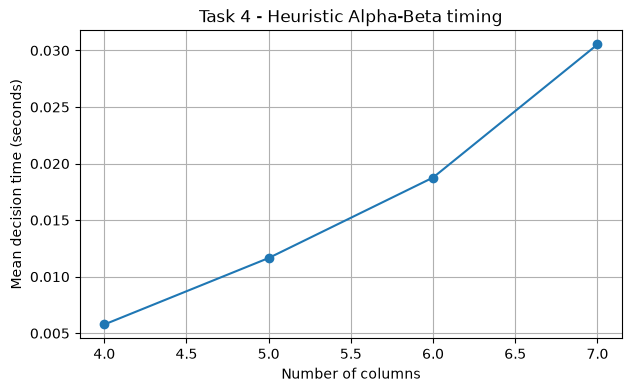

Heuristic Alpha-Beta trên bàn chuẩn 6x7:


,Rows,Columns,Connect,Depth,Mean time (s),Std time (s),Mean nodes,Mean cutoffs
0,6,7,4,3,0.038248,0.008715,129.0,17.0


In [59]:
def benchmark_heuristic(widths=(4, 5, 6, 7), rows=4, connect_n=3,
                        depth=3, repeats=5):
    records = []
    for cols in widths:
        board = empty_board((rows, cols))
        # Warm-up để giảm ảnh hưởng của chi phí khởi tạo ở lần gọi đầu.
        heuristic_alpha_beta(
            board, RED, connect_n=connect_n, depth=depth
        )
        times, nodes, cutoffs = [], [], []
        for _ in range(repeats):
            start = time.perf_counter()
            action, stats = heuristic_alpha_beta(
                board, RED, connect_n=connect_n, depth=depth
            )
            times.append(time.perf_counter() - start)
            nodes.append(stats["nodes"])
            cutoffs.append(stats["cutoffs"])
        records.append({
            "Rows": rows, "Columns": cols, "Connect": connect_n,
            "Depth": depth, "Mean time (s)": np.mean(times),
            "Std time (s)": np.std(times), "Mean nodes": np.mean(nodes),
            "Mean cutoffs": np.mean(cutoffs)
        })
    return pd.DataFrame(records)

heuristic_timing_df = benchmark_heuristic()
display(heuristic_timing_df)
plt.figure(figsize=(7, 4))
plt.plot(heuristic_timing_df["Columns"],
         heuristic_timing_df["Mean time (s)"], marker="o")
plt.xlabel("Number of columns")
plt.ylabel("Mean decision time (seconds)")
plt.title("Task 4 - Heuristic Alpha-Beta timing")
plt.grid(True)
plt.show()
# Bổ sung phép đo Heuristic Alpha-Beta trên bàn chuẩn 6x7.
standard_heuristic_timing_df = benchmark_heuristic(
    widths=(7,), rows=6, connect_n=4, depth=3, repeats=3
)
print("Heuristic Alpha-Beta trên bàn chuẩn 6x7:")
display(standard_heuristic_timing_df)


### Thời gian của Heuristic Alpha-Beta

Thí nghiệm giữ depth và connect_n cố định, tăng số cột từ 4 đến 7. Heuristic cần duyệt các cửa sổ trên bàn tại các nút cutoff, nên mỗi nút có chi phí đánh giá lớn hơn so với trả về 0 của Task 3. Đổi lại, thông tin đánh giá tốt hơn có thể giúp thứ tự tìm kiếm/cắt tỉa hiệu quả hơn. Đọc bảng và biểu đồ để so sánh thực tế; không mặc định heuristic luôn nhanh hơn Minimax cơ bản.

**Kết quả lần chạy:** trên bàn 4 hàng, Connect 3, depth 3, số nút lần lượt là 45, 67, 94 và 126 khi tăng từ 4 đến 7 cột; thời gian đo được khoảng 0,00280 s; 0,00472 s; 0,00827 s; 0,01969 s. Trên bàn chuẩn 6 × 7, Connect 4, depth 3, thuật toán xét 129 nút và mất khoảng 0,01711 s. So với Minimax cutoff trung tính, heuristic tốn thêm thời gian tại các nút lá vì phải quét các cửa sổ trên bàn cờ, nhưng cung cấp thông tin đánh giá chiến lược tốt hơn.


### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

Winner (+1 RED / -1 YELLOW / 0 draw): 0
Number of plies: 15
Final board:


,0,1,2,3,4
0,0,-1,0,0,1
1,0,-1,1,0,-1
2,0,-1,-1,0,1
3,1,1,1,0,1


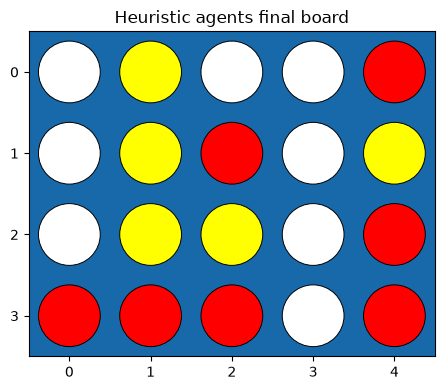

In [60]:
weights_agent_1 = {1: 1, 2: 8, 3: 80, 4: 100000}
weights_agent_2 = {1: 2, 2: 12, 3: 120, 4: 100000}

agent_depth_2 = make_heuristic_agent(
    depth=2, connect_n=3, weights=weights_agent_1
)
agent_depth_3 = make_heuristic_agent(
    depth=3, connect_n=3, weights=weights_agent_2
)

# Một trận theo yêu cầu; đổi màu để agent thứ hai không luôn đi sau.
competition = play_game(
    agent_depth_2, agent_depth_3,
    shape=(4, 5), connect_n=3, max_plies=100, verbose=False
)
print("Winner (+1 RED / -1 YELLOW / 0 draw):", competition["winner"])
print("Number of plies:", competition["plies"])
print("Final board:")
display(pd.DataFrame(competition["board"]))
visualize(competition["board"], title="Heuristic agents final board")

### Hai Heuristic Agent thi đấu

Hai tác tử dùng cutoff khác nhau (depth 2 và depth 3) và bộ trọng số khác nhau. Đây là một trận trên bàn 4 × 4, Connect 3 để đáp ứng yêu cầu thử nghiệm trên bàn có kích thước vừa phải. Bảng kết thúc cho biết người thắng (`+1` RED, `-1` YELLOW, `0` hòa) và số lượt.

Do chỉ có một trận và hai tác tử mang cấu hình khác nhau, kết quả không đủ để kết luận cấu hình nào tốt hơn một cách tổng quát. Muốn kết luận đáng tin cậy hơn cần đổi màu xuất phát, chạy nhiều ván và so sánh tỷ lệ thắng cũng như thời gian chọn nước.

**Kết quả lần chạy:** Agent RED (depth 2, bộ trọng số thứ nhất) thắng Agent YELLOW (depth 3, bộ trọng số thứ hai) sau 13 lượt. Đây chỉ là một ván theo yêu cầu notebook; một kết quả đơn lẻ không đủ chứng minh depth 2 hoặc bộ trọng số thứ nhất tốt hơn. Muốn kết luận cần chạy nhiều ván và đổi màu xuất phát.


## So sánh hành vi tác tử: Connect 4 và Mean Connect 4

Để so sánh công bằng, phần mở rộng này dùng cùng kích thước bàn 4 × 4, cùng luật Connect 3 và cùng độ sâu tìm kiếm. Điểm khác biệt duy nhất là bộ hành động: Connect 4 thường chỉ có Drop; Mean Connect 4 có thêm hành động chuyển quân đối thủ ở hàng đáy.

Ba phép so sánh được thực hiện:
1. **Branching factor:** đếm số hành động hợp lệ trên bàn rỗng và sau hai nước Drop. Ở bàn rỗng, hai trò chơi có cùng số hành động vì chưa có quân đối thủ ở hàng đáy; sau khi có quân, Mean Connect 4 có thể có nhiều hành động hơn.
2. **Minimax/Alpha-Beta:** so sánh thời gian, số nút và số lần cắt tỉa ở cùng độ sâu. Số hành động tăng thường làm cây Mean Connect 4 lớn hơn.
3. **Random vs Random:** so sánh tỷ lệ thắng/thua/hòa và số lượt trung bình trong cùng số ván. Đây là so sánh hành vi ngẫu nhiên, không phải kết luận về sức mạnh tối ưu của trò chơi.

Khi thảo luận, cần lưu ý RED luôn đi trước; do đó chênh lệch tỷ lệ thắng không chỉ do luật chơi. Muốn đánh giá tác tử có chiến lược, có thể thay Random Agent bằng cùng một cấu hình Heuristic Agent cho cả hai bộ luật. Các số liệu trong bảng phải lấy từ output notebook sau khi chạy.

**Kết quả lần chạy trên bàn 4 × 4, Connect 3:** bàn rỗng có 4 hành động trong cả hai trò chơi. Sau hai nước Drop, Connect 4 thường vẫn có 4 hành động, còn Mean Connect 4 có 7 hành động do xuất hiện thêm 3 lựa chọn di chuyển quân đối thủ. Ở Alpha-Beta depth 4 trên bàn rỗng, Connect 4 xét 61 nút (khoảng 0,00067 s), trong khi Mean Connect 4 xét 127 nút (khoảng 0,00215 s). Điều này minh họa chi phí tìm kiếm tăng do luật Mean Move.

Trong 200 ván Random-vs-Random mỗi biến thể, Connect 4 có RED thắng 129, YELLOW thắng 67, hòa 4; Mean Connect 4 có RED thắng 146, YELLOW thắng 47, hòa 7. Số lượt trung bình lần lượt là 9,015 và 9,94. Cả hai thí nghiệm đều có RED đi trước, nên không thể quy toàn bộ chênh lệch cho riêng luật Mean Move. Kết quả cho thấy Mean Move làm thay đổi tập hành động và kéo dài ván trung bình trong cấu hình thử nghiệm này.


In [61]:
def standard_actions(board, player, connect_n=4):
    """Hành động của Connect 4 thường: chỉ có Drop, không có Mean Move."""
    if get_winners(board, connect_n):
        return []
    return [("drop", col) for col in range(board.shape[1])
            if board[0, col] == EMPTY]

def standard_result(board, action, player, connect_n=4):
    """Transition của Connect 4 thường."""
    if action[0] != "drop":
        raise ValueError("Connect 4 thường chỉ hỗ trợ hành động drop.")
    return result(board, action, player, connect_n)

def generic_alpha_beta(board, player, actions_fn, result_fn,
                       connect_n=4, depth=3):
    """Alpha-Beta dùng chung cho hai luật, không dùng move ordering."""
    stats = {"nodes": 0, "cutoffs": 0}

    def search(state, to_move, remaining, alpha, beta, path):
        stats["nodes"] += 1
        winners = get_winners(state, connect_n)
        if winners:
            u = utility(state, connect_n)
            return u
        if remaining == 0:
            return 0
        key = board_key(state, to_move)
        if key in path:
            return 0
        next_path = path | {key}
        legal = actions_fn(state, to_move, connect_n)
        if not legal:
            return 0

        if to_move == RED:
            value = -float("inf")
            for action in legal:
                child = result_fn(state, action, to_move, connect_n)
                value = max(value, search(
                    child, -to_move, remaining - 1,
                    alpha, beta, next_path))
                alpha = max(alpha, value)
                if alpha >= beta:
                    stats["cutoffs"] += 1
                    break
        else:
            value = float("inf")
            for action in legal:
                child = result_fn(state, action, to_move, connect_n)
                value = min(value, search(
                    child, -to_move, remaining - 1,
                    alpha, beta, next_path))
                beta = min(beta, value)
                if alpha >= beta:
                    stats["cutoffs"] += 1
                    break
        return value

    legal_root = actions_fn(board, player, connect_n)
    if not legal_root:
        return None, stats
    best_action = legal_root[0]
    best_value = -float("inf") if player == RED else float("inf")
    alpha, beta = -float("inf"), float("inf")
    for action in legal_root:
        child = result_fn(board, action, player, connect_n)
        value = search(child, -player, depth - 1,
                       alpha, beta, frozenset({board_key(board, player)}))
        if player == RED and value > best_value:
            best_value, best_action = value, action
        elif player == YELLOW and value < best_value:
            best_value, best_action = value, action
        if player == RED:
            alpha = max(alpha, best_value)
        else:
            beta = min(beta, best_value)
    return best_action, stats

def play_variant_game(red_agent, yellow_agent, actions_fn, result_fn,
                      shape=(4, 4), connect_n=3, max_plies=100):
    board = empty_board(shape)
    player = RED
    agents = {RED: red_agent, YELLOW: yellow_agent}
    plies = 0
    for _ in range(max_plies):
        if get_winners(board, connect_n):
            break
        legal = actions_fn(board, player, connect_n)
        if not legal:
            break
        action = agents[player](board.copy(), player)
        if action not in legal:
            raise ValueError(f"Agent returned invalid action: {action}")
        board = result_fn(board, action, player, connect_n)
        plies += 1
        if get_winners(board, connect_n):
            break
        player *= -1
    return {"winner": utility(board, connect_n), "plies": plies,
            "capped": plies >= max_plies, "board": board}

def random_agent_for(actions_fn, connect_n=4):
    def agent(board, player=RED):
        legal = actions_fn(board, player, connect_n)
        return random.choice(legal) if legal else None
    return agent

def compare_random_games(n_games=200, shape=(4, 4), connect_n=3,
                         max_plies=100, seed=2026):
    """Random-vs-random so sánh hai bộ luật trong cùng cấu hình."""
    rows = []
    random.seed(seed)
    for game_id in range(n_games):
        for game_name, acts_fn, res_fn in [
            ("Connect 4", standard_actions, standard_result),
            ("Mean Connect 4", actions, result)
        ]:
            variant_random = random_agent_for(acts_fn, connect_n)
            outcome = play_variant_game(
                variant_random, variant_random, acts_fn, res_fn,
                shape, connect_n, max_plies
            )
            rows.append({
                "Game": game_id + 1, "Variant": game_name,
                "Winner": outcome["winner"], "Plies": outcome["plies"],
                "Capped": outcome["capped"]
            })
    raw = pd.DataFrame(rows)
    summary = raw.groupby("Variant").agg(
        RED_wins=("Winner", lambda x: int((x == RED).sum())),
        YELLOW_wins=("Winner", lambda x: int((x == YELLOW).sum())),
        Draws=("Winner", lambda x: int((x == 0).sum())),
        Mean_plies=("Plies", "mean"),
        Capped_games=("Capped", "sum")
    ).reset_index()
    return raw, summary

# So sánh số hành động ban đầu và sau một lượt trên cùng kích thước 4x4.
comparison_board = empty_board((4, 4))
standard_opening_actions = standard_actions(comparison_board, RED, 3)
mean_opening_actions = actions(comparison_board, RED, 3)

# Tạo trạng thái sau 2 nước Drop giống nhau để xem Mean Move làm branching tăng ra sao.
after_two_drops = result(comparison_board, ("drop", 1), RED, 3)
after_two_drops = result(after_two_drops, ("drop", 2), YELLOW, 3)

branching_df = pd.DataFrame([
    {"State": "Empty board", "Variant": "Connect 4",
     "Legal actions": len(standard_actions(comparison_board, RED, 3))},
    {"State": "Empty board", "Variant": "Mean Connect 4",
     "Legal actions": len(actions(comparison_board, RED, 3))},
    {"State": "After two drops", "Variant": "Connect 4",
     "Legal actions": len(standard_actions(after_two_drops, RED, 3))},
    {"State": "After two drops", "Variant": "Mean Connect 4",
     "Legal actions": len(actions(after_two_drops, RED, 3))}
])
display(branching_df)

# So sánh Minimax/Alpha-Beta cùng độ sâu trên bàn rỗng.
search_comparison = []
for variant, acts_fn, res_fn in [
    ("Connect 4", standard_actions, standard_result),
    ("Mean Connect 4", actions, result)
]:
    elapsed = []
    node_counts = []
    cutoff_counts = []
    chosen = None
    for _ in range(3):
        start = time.perf_counter()
        chosen, stats = generic_alpha_beta(
            empty_board((4, 4)), RED, acts_fn, res_fn,
            connect_n=3, depth=4
        )
        elapsed.append(time.perf_counter() - start)
        node_counts.append(stats["nodes"])
        cutoff_counts.append(stats["cutoffs"])
    search_comparison.append({
        "Variant": variant, "Depth": 4, "Chosen action": chosen,
        "Mean time (s)": np.mean(elapsed),
        "Mean nodes": np.mean(node_counts),
        "Mean cutoffs": np.mean(cutoff_counts)
    })
search_comparison_df = pd.DataFrame(search_comparison)
display(search_comparison_df)

# Random-vs-random matchups; this compares behavior, not playing strength.
comparison_games_df, comparison_summary_df = compare_random_games(
    n_games=200, shape=(4, 4), connect_n=3, max_plies=100
)
display(comparison_summary_df)

,State,Variant,Legal actions
0,Empty board,Connect 4,4
1,Empty board,Mean Connect 4,4
2,After two drops,Connect 4,4
3,After two drops,Mean Connect 4,7


,Variant,Depth,Chosen action,Mean time (s),Mean nodes,Mean cutoffs
0,Connect 4,4,"(drop, 0)",0.001402,61.0,21.0
1,Mean Connect 4,4,"(drop, 0)",0.002473,127.0,33.0


,Variant,RED_wins,YELLOW_wins,Draws,Mean_plies,Capped_games
0,Connect 4,129,67,4,9.015,0
1,Mean Connect 4,146,47,7,9.940,0


## Tournament task [+ 1 to 5 bonus point will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [1 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+1 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (see [tic-tac-toe-example](tictactoe_pure_monte_carlo_search.ipynb)) and investigate how this search performs on the test boards that you have used above. 